# Homework 7

## 1(a) Training and test sets

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

csv = Path("Frogs_MFCCs.csv")
if not csv.is_file():
    csv = Path("/Users/yuxinyang/Documents/Course_26F/DSCI-552/PDF New Homework- 8 Sets/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")
data = pd.read_csv(csv)
X = data.filter(regex="^MFCC").to_numpy()
Y = data[["Family", "Genus", "Species"]]
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, train_size=0.70, random_state=42
)
print(f"Training: {len(y_train)}, test: {len(y_test)}")

Training: 5036, test: 2159


## 1(b)(i) Multilabel metrics

Exact match is the fraction of observations with all three labels correct. Hamming loss is the fraction of individual label positions predicted incorrectly. Hamming score is the fraction predicted correctly, or one minus Hamming loss.

In [2]:
def scores(actual, predicted):
    wrong = np.asarray(actual) != np.asarray(predicted)
    return {
        "Exact match": (~wrong.any(axis=1)).mean(),
        "Hamming score": 1 - wrong.mean(),
        "Hamming loss": wrong.mean(),
    }

## 1(b)(ii–iv) Gaussian, L1, and class-weighted L1 SVMs

Fit one one-vs-rest model per target. Select hyperparameters by mean balanced accuracy across 10 stratified folds. The Gaussian SVM uses raw MFCCs and kernel width σ = 1/√(2γ). Both L1 SVMs standardize inside each fold. The class-weighted model gives each class weight inversely proportional to its training frequency.

In [3]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

models = {
    "Gaussian": (OneVsRestClassifier(SVC()), {
        "estimator__C": [0.1, 1, 10, 100],
        "estimator__gamma": [0.1, 1, 10, 100],
    }),
    **{
        name: (make_pipeline(StandardScaler(), LinearSVC(
            penalty="l1", dual=False, class_weight=weight, max_iter=200000, random_state=42
        )), {"linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100]})
        for name, weight in [("L1", None), ("Weighted L1", "balanced")]
    },
}
cv = StratifiedKFold(10, shuffle=True, random_state=42)
tuning, results = [], {}
for name, (model, grid) in models.items():
    predicted = pd.DataFrame(index=y_test.index)
    for target in Y:
        search = GridSearchCV(model, grid, cv=cv, scoring="balanced_accuracy", n_jobs=1)
        search.fit(X_train, y_train[target])
        predicted[target] = search.predict(X_test)
        params = search.best_params_
        gamma = params.get("estimator__gamma", np.nan)
        tuning.append({
            "Model": name, "Target": target,
            "C": next(value for key, value in params.items() if key.endswith("__C")),
            "Sigma": 1 / np.sqrt(2 * gamma),
            "CV balanced accuracy": search.best_score_,
            "Test balanced accuracy": balanced_accuracy_score(y_test[target], predicted[target]),
        })
    results[name] = scores(y_test, predicted)

tuning = pd.DataFrame(tuning)
results = pd.DataFrame(results).T
display(tuning.round(4), results.round(4))
best_exact = results["Exact match"].idxmax()
best_hamming = results["Hamming loss"].idxmin()
balanced = tuning.groupby("Model")["Test balanced accuracy"].mean()
change = balanced["Weighted L1"] - balanced["L1"]
print(f"{best_exact} had the highest exact match. {best_hamming} had the lowest Hamming loss.")
print(f"Class weighting changed mean test balanced accuracy by {100 * change:+.2f} percentage points.")

,Model,Target,C,Sigma,CV balanced accuracy,Test balanced accuracy
0,Gaussian,Family,100,0.7071,0.9685,0.9798
1,Gaussian,Genus,10,0.7071,0.9705,0.9656
2,Gaussian,Species,10,0.7071,0.9705,0.9750
3,L1,Family,10,NaN,0.6993,0.6902
4,L1,Genus,100,NaN,0.7948,0.7690
5,L1,Species,100,NaN,0.8887,0.8948
6,Weighted L1,Family,100,NaN,0.9141,0.9039
7,Weighted L1,Genus,1,NaN,0.8887,0.8981
8,Weighted L1,Species,10,NaN,0.9076,0.9105


,Exact match,Hamming score,Hamming loss
Gaussian,0.9875,0.9923,0.0077
L1,0.9125,0.9430,0.0570
Weighted L1,0.9064,0.9409,0.0591


Gaussian had the highest exact match. Gaussian had the lowest Hamming loss.
Class weighting changed mean test balanced accuracy by +11.95 percentage points.


## 2(a–c) K-means Monte Carlo simulation

In each of 50 runs, fit k-means to all MFCCs for k = 1,…,50. Select the elbow by maximizing the vertical gap between normalized inertia and the chord joining the first and last points. Assign each cluster the mode of each true label. Hamming distance counts mismatched positions per observation, so Hamming loss is the mean distance divided by three.

In [4]:
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits

ks = np.arange(1, 51)
runs = []
with threadpool_limits(limits=1):
    for seed in range(50):
        fits = [KMeans(n_clusters=int(k), n_init=1, random_state=seed).fit(X) for k in ks]
        inertia = np.array([fit.inertia_ for fit in fits])
        normalized = (inertia - inertia[-1]) / (inertia[0] - inertia[-1])
        best = np.argmax(np.linspace(1, 0, len(ks)) - normalized)
        clusters = fits[best].labels_
        majority = Y.groupby(clusters).agg(lambda labels: labels.mode().iat[0])
        predicted = majority.loc[clusters, Y.columns].to_numpy()
        distance = (Y.to_numpy() != predicted).sum(axis=1).mean()
        loss = distance / Y.shape[1]
        runs.append((ks[best], distance, 1 - loss, loss))

runs = pd.DataFrame(runs, columns=["k", "Hamming distance", "Hamming score", "Hamming loss"])
display(runs.describe().loc[["mean", "std"], ["Hamming distance", "Hamming score", "Hamming loss"]].round(4))

,Hamming distance,Hamming score,Hamming loss
mean,0.4734,0.8422,0.1578
std,0.0706,0.0235,0.0235


## 3. ISLR §12.6, Exercise 2

- **(a) Complete linkage:** Merge {1, 2} at 0.30 and {3, 4} at 0.45. Merge those pairs at 0.80.
- **(b) Single linkage:** Merge {1, 2} at 0.30, add 3 at 0.40, then add 4 at 0.45.
- **(c)** Cutting complete linkage at 0.60 gives {1, 2} and {3, 4}.
- **(d)** Cutting single linkage at 0.425 gives {1, 2, 3} and {4}.
- **(e)** Swap the two branches of the final complete-linkage merge to get leaf order 3, 4, 1, 2.

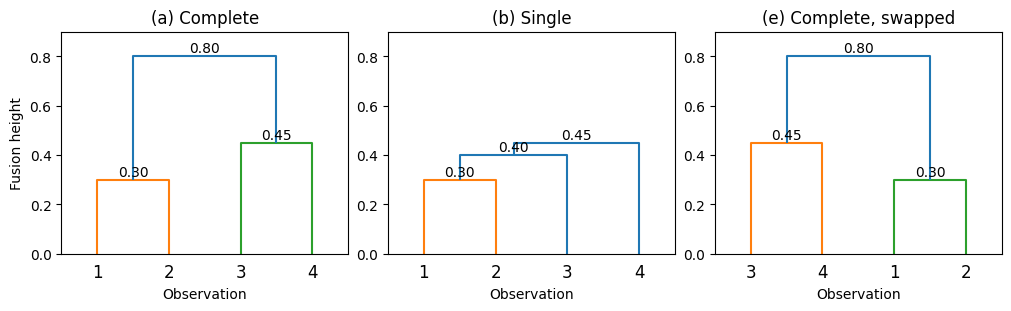

In [5]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

complete = np.array([[0, 1, .30, 2], [2, 3, .45, 2], [4, 5, .80, 4]])
single = np.array([[0, 1, .30, 2], [4, 2, .40, 3], [5, 3, .45, 4]])
swapped = complete.copy()
swapped[-1, :2] = [5, 4]

fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout="constrained")
for ax, title, tree in zip(axes, ["(a) Complete", "(b) Single", "(e) Complete, swapped"],
                           [complete, single, swapped]):
    plot = dendrogram(tree, labels=["1", "2", "3", "4"], ax=ax)
    for x, y in zip(plot["icoord"], plot["dcoord"]):
        ax.text((x[1] + x[2]) / 2, y[1] + .015, f"{y[1]:.2f}", ha="center")
    ax.set(title=title, xlabel="Observation", ylim=(0, .9))
axes[0].set_ylabel("Fusion height")
plt.show()